# Experimentación — control de medidas y peso del catálogo Turbo

Notebook reproducible del flujo completo, paso por paso, sobre los **datos sintéticos** del repo
(mismos patrones de error que la corrida real contra Snowflake, sin exponer datos internos).

Corre sin credenciales (modo offline). Con `ANTHROPIC_API_KEY` y `LLAMA_CLOUD_API_KEY` en el entorno,
las mismas celdas usan el modelo de visión y LlamaCloud reales.

In [1]:
import os, sys, json
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, str(Path.cwd()))
os.environ.setdefault("TURBO_STATE_DIR", ".state_notebook")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
from src.config import Umbrales
from src.observabilidad import configurar_logs
configurar_logs()
U = Umbrales()
print("umbrales", U.version)

umbrales v1


## 1. Carga + Capa 1 (validación de entrada determinística)

In [2]:
from src.datos import cargar_catalogo, estandarizar, validar_entrada
from src.detector import asignar_grupo
df, fuente = cargar_catalogo()
df = asignar_grupo(validar_entrada(estandarizar(df), U), U)
print(fuente, len(df), "SKUs")
df[df.MOTIVO_ENTRADA.notna()][["SKU_ID", "PRODUCT_NAME", "MOTIVO_ENTRADA"]]

{"ts": "2026-10-12T23:52:20.511+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": null, "sku_id": "GSE-001", "motivo": "PESO_KG=1550.0 fuera de rango físico [0.001, 50.0]", "estado": "dato_incompleto"}


{"ts": "2026-10-12T23:52:20.512+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": null, "sku_id": "SNK-008", "motivo": "falta ALTO_CM", "estado": "dato_incompleto"}


csv_muestra 59 SKUs


,SKU_ID,PRODUCT_NAME,MOTIVO_ENTRADA
0,GSE-001,"Gaseosa Cola Andina 1,5 L","PESO_KG=1550.0 fuera de rango físico [0.001, 50.0]"
33,SNK-008,Papas Fritas Cheddar Ruta 150 g,falta ALTO_CM


Estandarización de unidades: *Entraña 500 g* viene en `G` y el resto de la subcategoría en `KG`. Llevado a unidad estándar, es consistente.

In [3]:
df[df.SUBCATEGORY_NAME == "Res"][["SKU_ID", "PRODUCT_NAME", "NET_QUANTITY", "MEASUREMENT_UNIT", "NET_STD"]]

,SKU_ID,PRODUCT_NAME,NET_QUANTITY,MEASUREMENT_UNIT,NET_STD
44,RES-001,Bife de Chorizo Estancia 500 g,0.5,KG,0.5
45,RES-002,Vacío Estancia 500 g,0.5,KG,0.5
46,RES-003,Cuadril Estancia 500 g,0.5,KG,0.5
47,RES-004,Entraña Estancia 500 g,500.0,G,0.5
48,RES-005,Matambre Estancia 500 g,0.5,KG,0.5


## 2. Agente 1 — rangos IQR por subcategoría + validador de unidades

In [4]:
from src.detector import detectar
cola, rangos = detectar(df, U)
print(len(rangos), "pares (grupo, campo) con rango;", cola.SKU_ID.nunique(), "SKUs marcados")
cola[["SKU_ID", "CAMPO", "VALOR", "RANGO_LO", "RANGO_HI", "DESVIO_PCT", "ROTACION", "PRIORIDAD"]]

32 pares (grupo, campo) con rango; 10 SKUs marcados


,SKU_ID,CAMPO,VALOR,RANGO_LO,RANGO_HI,DESVIO_PCT,ROTACION,PRIORIDAD
0,SNK-003,peso_kg,0.210,0.1550,0.1950,7.7,alta,1
1,GSE-009,peso_kg,6.400,1.4974,1.6826,280.4,media,2
2,BAR-001,net_quantity,0.000,NaN,NaN,100.0,media,2
3,QUE-005,peso_kg,0.550,0.3131,0.3544,55.2,media,2
4,BAR-001,peso_kg,0.020,0.0285,0.0315,29.8,media,2
5,BAR-001,ancho_cm,3.000,3.0400,3.3600,1.3,media,2
6,BAR-001,alto_cm,1.700,1.7100,1.8900,0.6,media,2
7,YOG-004,peso_kg,10.300,0.9874,1.1051,832.0,baja,3
8,BAR-006,peso_kg,0.085,0.0285,0.0315,169.8,baja,3
9,BAR-006,alto_cm,4.500,1.7100,1.8900,138.1,baja,3


## 3. Parsing de fichas técnicas (LlamaCloud → fallback pypdf) y filtro de campos comerciales

In [5]:
from src.parsing import parsear_fichas
salidas = parsear_fichas()
print([p.name for p in salidas])
print(salidas[0].read_text(encoding="utf-8")[:900])

{"ts": "2026-10-12T23:52:20.779+00:00", "level": "WARNING", "logger": "turbo", "msg": "usando ruta alternativa", "trace_id": null, "etapa": "parsing", "motivo": "ErrorPermanente", "detalle": "sin LLAMA_CLOUD_API_KEY"}


{"ts": "2026-10-12T23:52:20.796+00:00", "level": "WARNING", "logger": "turbo", "msg": "usando ruta alternativa", "trace_id": null, "etapa": "parsing", "motivo": "ErrorPermanente", "detalle": "sin LLAMA_CLOUD_API_KEY"}


['lacteos_del_sur.md', 'snacks_pampa.md']
<!-- fuente: lacteos_del_sur.pdf | parser: pypdf -->
# Ficha técnica de productos — Lácteos del Sur S.A. (PRV-LAC)
Documento para clientes mayoristas. Versión 2026-09.

## Producto YOG-004 — Yogur Bebible Natural Pampa 1 kg

| Atributo | Valor |
|---|---|
| Código cliente | YOG-004 |
| Contenido neto | 1 kg |
| Peso bruto unidad | 1,05 kg |
| Dimensiones unidad (L x A x H) | 8,5 x 8,5 x 23,5 cm |

## Producto YOG-006 — Yogur Bebible Vainilla Sur 1 kg

| Atributo | Valor |
|---|---|
| Código cliente | YOG-006 |
| Contenido neto | 1 kg |
| Peso bruto unidad | 1,04 kg |
| Dimensiones unidad (L x A x H) | 8,6 x 8,6 x 23,5 cm |

## Producto QUE-005 — Queso Untable Ciboulette Sur 300 g

| Atributo | Valor |
|---|---|
| Código cliente | QUE-005 |
| Contenido neto | 300 g |
| Peso bruto unidad | 0,33 kg |
| Dimensiones unidad (L x A x H) | 10,8 x 10,8 x 6,2 cm |

## Producto QUE-004 — Queso Unta


## 4. Base vectorial (Chroma) y búsqueda híbrida

In [6]:
from src.rag import BaseConocimiento, extraer_valores
kb = BaseConocimiento(persistir=False, nombre="notebook")
print("chunks:", kb.indexar(), "| embeddings:", kb.modelo_embedding)
hits = kb.buscar("QUE-005 Queso Untable Ciboulette Sur 300 g peso bruto dimensiones", "QUE-005", U)
for h in hits:
    print(f"{h['fuente']:20} {h['id']:24} sim={h['similitud']}  ->", extraer_valores(h["texto"]))

{"ts": "2026-10-12T23:52:22.058+00:00", "level": "WARNING", "logger": "turbo", "msg": "modelo de embeddings no disponible, uso hashing local", "trace_id": null, "error": "ProxyError"}


chunks: 12 | embeddings: hash-local-512
ficha_proveedor      lacteos_del_sur.md#2     sim=0.468  -> {'peso_kg': 0.33, 'largo_cm': 10.8, 'alto_cm': 6.2, 'ancho_cm': 10.8, 'net_quantity_g': 300.0}
catalogo_fabricante  QUE-005.md#0             sim=0.431  -> {'peso_kg': 0.55, 'largo_cm': 12.0, 'alto_cm': 7.0, 'ancho_cm': 12.0, 'net_quantity_g': None}


Dos fuentes **oficiales** dicen cosas distintas (0,33 kg vs 0,55 kg): el sistema no elige solo.

## 5. Multimodal — lectura del rótulo logístico

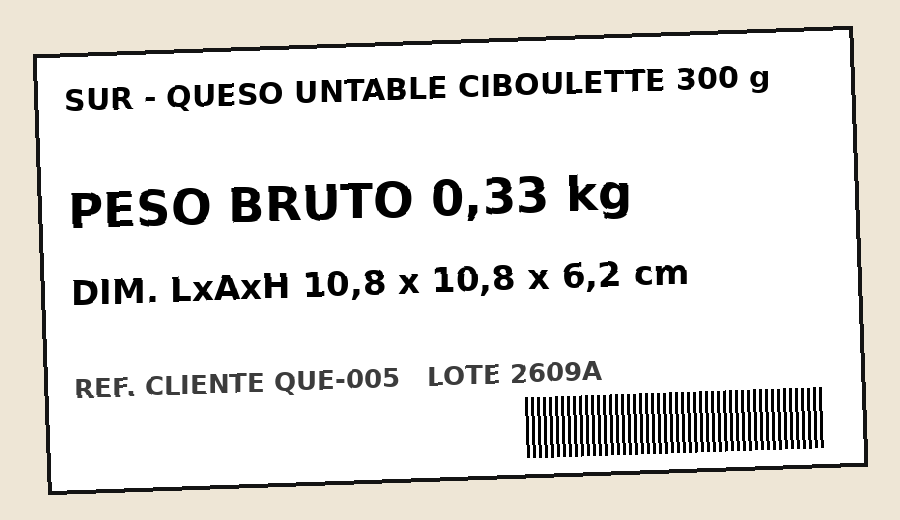

{'peso_kg': 0.33,
 'dims': [10.8, 10.8, 6.2],
 'legible': True,
 'archivo': 'QUE-005.png',
 'ruta': 'grabada'}

In [7]:
from IPython.display import Image, display
from src.vision import leer_rotulo
display(Image("data/fotos/QUE-005.png", width=450))
leer_rotulo("QUE-005")

## 6. Agente 2 — investigación de toda la cola

In [8]:
from src.agente2 import Investigador
inv = Investigador(kb, df, rangos, U)
res = [inv.investigar(f) for _, f in cola.iterrows()]
pd.DataFrame([{"sku": r.sku_id, "campo": r.campo, "estado": r.estado, "accion": r.accion_propuesta,
               "actual": r.valor_actual, "propuesto": r.valor_propuesto, "confianza": r.confianza,
               "fuentes": ",".join(e.fuente for e in r.evidencias), "motivo": r.motivo[:70]} for r in res])

,sku,campo,estado,accion,actual,propuesto,confianza,fuentes,motivo
0,SNK-003,peso_kg,pendiente_aprobacion,corregir_y_notificar,0.210,0.17,alta,"ficha_proveedor,foto_etiqueta",requiere aprobación: alta rotación
1,GSE-009,peso_kg,bloqueado_pendiente_aprobacion,bloquear_pendiente_aprobacion,6.400,NaN,NaN,,sin fuente permitida y desvío 280.4% > 30.0%: riesgo de despacho/slott
2,BAR-001,net_quantity,pendiente_aprobacion,corregir_y_notificar,0.000,16.00,alta,ficha_proveedor,requiere aprobación: desvío 100.0% > 30.0%
3,QUE-005,peso_kg,fuentes_contradictorias,ninguna,0.550,NaN,NaN,"ficha_proveedor,catalogo_fabricante,foto_etiqueta",dos fuentes oficiales difieren; decide el analista: ficha_proveedor=0.
4,BAR-001,peso_kg,ok,ninguna,0.020,0.02,alta,ficha_proveedor,"valor confirmado por ficha_proveedor: falso positivo del rango, sin ca"
5,BAR-001,ancho_cm,ok,ninguna,3.000,3.00,alta,ficha_proveedor,"valor confirmado por ficha_proveedor: falso positivo del rango, sin ca"
6,BAR-001,alto_cm,ok,ninguna,1.700,1.70,alta,ficha_proveedor,"valor confirmado por ficha_proveedor: falso positivo del rango, sin ca"
7,YOG-004,peso_kg,pendiente_aprobacion,corregir_y_notificar,10.300,1.05,alta,"ficha_proveedor,catalogo_fabricante",requiere aprobación: desvío 832.0% > 30.0%
8,BAR-006,peso_kg,bloqueado_pendiente_aprobacion,bloquear_pendiente_aprobacion,0.085,NaN,NaN,,sin fuente permitida y desvío 169.8% > 30.0%: riesgo de despacho/slott
9,BAR-006,alto_cm,bloqueado_pendiente_aprobacion,bloquear_pendiente_aprobacion,4.500,NaN,NaN,,sin fuente permitida y desvío 138.1% > 30.0%: riesgo de despacho/slott


## 7. Evaluación automática contra el golden set (offline) — v1 vs. candidata v2

In [9]:
from dataclasses import replace
from src.evals import evaluar
v1 = evaluar(U, "v1")
v2 = evaluar(replace(U, version="v2", separar_packs=True), "v2")
cols = ["exactitud_estado", "detector_precision", "detector_recall", "exactitud_valor_propuesto", "fidelidad_fuente"]
display(pd.DataFrame({"v1": {c: v1[c] for c in cols}, "v2": {c: v2[c] for c in cols}}))
print("errores v1:", v1["errores"])
print("errores v2:", v2["errores"])

{"ts": "2026-10-12T23:52:22.702+00:00", "level": "WARNING", "logger": "turbo", "msg": "modelo de embeddings no disponible, uso hashing local", "trace_id": null, "error": "ProxyError"}


{"ts": "2026-10-12T23:52:22.711+00:00", "level": "WARNING", "logger": "turbo", "msg": "usando ruta alternativa", "trace_id": null, "etapa": "parsing", "motivo": "ErrorPermanente", "detalle": "sin LLAMA_CLOUD_API_KEY"}


{"ts": "2026-10-12T23:52:22.725+00:00", "level": "WARNING", "logger": "turbo", "msg": "usando ruta alternativa", "trace_id": null, "etapa": "parsing", "motivo": "ErrorPermanente", "detalle": "sin LLAMA_CLOUD_API_KEY"}


{"ts": "2026-10-12T23:52:22.771+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": "run-f170eccf36", "sku_id": "GSE-001", "motivo": "PESO_KG=1550.0 fuera de rango físico [0.001, 50.0]", "estado": "dato_incompleto"}


{"ts": "2026-10-12T23:52:22.772+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": "run-f170eccf36", "sku_id": "SNK-008", "motivo": "falta ALTO_CM", "estado": "dato_incompleto"}


...

{"ts": "2026-10-12T23:52:23.345+00:00", "level": "WARNING", "logger": "turbo", "msg": "usando ruta alternativa", "trace_id": "run-f170eccf36", "etapa": "parsing", "motivo": "ErrorPermanente", "detalle": "sin LLAMA_CLOUD_API_KEY"}


{"ts": "2026-10-12T23:52:23.389+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": "run-f9a45b2187", "sku_id": "GSE-001", "motivo": "PESO_KG=1550.0 fuera de rango físico [0.001, 50.0]", "estado": "dato_incompleto"}


{"ts": "2026-10-12T23:52:23.390+00:00", "level": "WARNING", "logger": "turbo", "msg": "SKU no pasa validación de entrada", "trace_id": "run-f9a45b2187", "sku_id": "SNK-008", "motivo": "falta ALTO_CM", "estado": "dato_incompleto"}


,v1,v2
exactitud_estado,0.9831,1.0
detector_precision,0.9167,1.0
detector_recall,1.0000,1.0
exactitud_valor_propuesto,1.0000,1.0
fidelidad_fuente,1.0000,1.0


errores v1: [{'sku_id': 'BAR-006', 'esperado': 'ok', 'obtenido': 'bloqueado_pendiente_aprobacion', 'nota': 'pack 3x25 g legítimo; v1 lo marca (falso positivo)'}]
errores v2: []


## 8. Jurado de fidelidad (IA como jurado / reglas en modo offline)

In [10]:
pd.DataFrame(v1["jurado"])[["sku_id", "campo", "respaldado", "juez", "cita", "explicacion"]]

,sku_id,campo,respaldado,juez,cita,explicacion
0,SNK-003,peso_kg,True,reglas,snacks_pampa.md#1,coincidencia literal en la evidencia citada
1,BAR-001,net_quantity,True,reglas,snacks_pampa.md#2,coincidencia literal en la evidencia citada
2,BAR-001,peso_kg,True,reglas,snacks_pampa.md#2,coincidencia literal en la evidencia citada
3,BAR-001,ancho_cm,True,reglas,snacks_pampa.md#2,coincidencia literal en la evidencia citada
4,BAR-001,alto_cm,True,reglas,snacks_pampa.md#2,coincidencia literal en la evidencia citada
5,YOG-004,peso_kg,True,reglas,lacteos_del_sur.md#0,coincidencia literal en la evidencia citada
6,YOG-006,alto_cm,True,reglas,lacteos_del_sur.md#1,coincidencia literal en la evidencia citada
7,GAL-007,peso_kg,True,reglas,snacks_pampa.md#0,coincidencia literal en la evidencia citada
8,SNK-005,peso_kg,True,reglas,SNK-005.png,coincidencia literal en la evidencia citada


## 9. KPIs de la corrida

In [11]:
print(json.dumps(v1["kpis_corrida"], indent=2, ensure_ascii=False))

{
  "skus_escaneados": 59,
  "conteo_estados": {
    "ok": 47,
    "pendiente_aprobacion": 5,
    "dato_incompleto": 2,
    "bloqueado_pendiente_aprobacion": 2,
    "corregido": 1,
    "fuentes_contradictorias": 1,
    "sin_fuente_confiable": 1
  },
  "tasa_finalizacion": 0.8136,
  "skus_a_revision_humana": 11,
  "tasa_inconsistencia_agente1": 0.1695,
  "latencia_agente1_s": 0.0615,
  "latencia_agente2_mediana_s": 0.0071,
  "latencia_agente2_p95_s": 0.0101,
  "costo_llm_usd_por_sku_investigado": 0.0
}
